In [1]:

# NIM: 202431146
# Nama: Fauzan Mubarak P
# Project UTS Pembelajaran Mesin

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Semua library berhasil diimport!")


Semua library berhasil diimport!


In [2]:

# NIM: 202431146
# Membaca dataset Bank Customers

df = pd.read_csv("04_bank_customers.csv", sep=";")

print("Ukuran dataset:", df.shape)

display(df.head())


Ukuran dataset: (45211, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [3]:

# NIM: 202431146
# Melihat informasi dataset

df.info()

print("\nJumlah baris:", df.shape[0])
print("Jumlah kolom:", df.shape[1])


<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        45211 non-null  int64
 1   job        45211 non-null  str  
 2   marital    45211 non-null  str  
 3   education  45211 non-null  str  
 4   default    45211 non-null  str  
 5   balance    45211 non-null  int64
 6   housing    45211 non-null  str  
 7   loan       45211 non-null  str  
 8   contact    45211 non-null  str  
 9   day        45211 non-null  int64
 10  month      45211 non-null  str  
 11  duration   45211 non-null  int64
 12  campaign   45211 non-null  int64
 13  pdays      45211 non-null  int64
 14  previous   45211 non-null  int64
 15  poutcome   45211 non-null  str  
 16  y          45211 non-null  str  
dtypes: int64(7), str(10)
memory usage: 8.1 MB

Jumlah baris: 45211
Jumlah kolom: 17


In [4]:

# NIM: 202431146
# Tahap EDA - Pemeriksaan Kualitas Data

print("=== MISSING VALUES ===")
print(df.isnull().sum())

print("\n=== DATA DUPLIKAT ===")
print("Jumlah duplikat:", df.duplicated().sum())

print("\n=== NILAI UNKNOWN ===")
for kolom in df.select_dtypes(include=["object", "str"]).columns:
    jumlah = (df[kolom] == "unknown").sum()
    print(f"{kolom}: {jumlah}")

print("\n=== STATISTIK DESKRIPTIF ===")
display(df.describe())


=== MISSING VALUES ===
age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64

=== DATA DUPLIKAT ===
Jumlah duplikat: 0

=== NILAI UNKNOWN ===
job: 288
marital: 0
education: 1857
default: 0
housing: 0
loan: 0
contact: 13020
month: 0
poutcome: 36959
y: 0

=== STATISTIK DESKRIPTIF ===


,age,balance,day,duration,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000


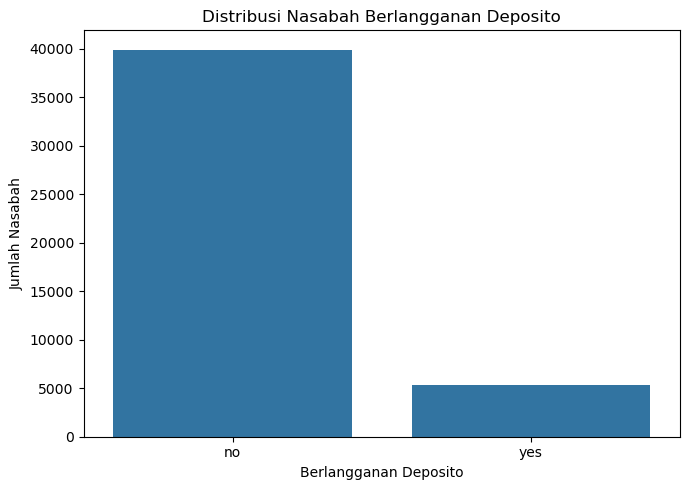

y
no     39922
yes     5289
Name: count, dtype: int64
y
no     88.30152
yes    11.69848
Name: proportion, dtype: float64


In [5]:

# NIM: 202431146
# EDA - Distribusi target deposito

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="y",
    order=["no", "yes"]
)

plt.title("Distribusi Nasabah Berlangganan Deposito")
plt.xlabel("Berlangganan Deposito")
plt.ylabel("Jumlah Nasabah")

plt.tight_layout()
plt.show()

print(df["y"].value_counts())
print(df["y"].value_counts(normalize=True) * 100)


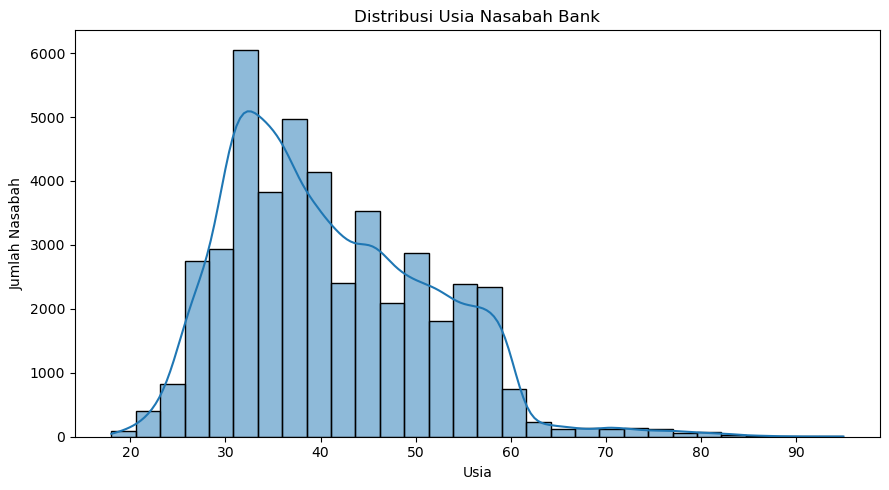

In [6]:

# NIM: 202431146
# EDA - Distribusi usia nasabah

plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="age",
    bins=30,
    kde=True
)

plt.title("Distribusi Usia Nasabah Bank")
plt.xlabel("Usia")
plt.ylabel("Jumlah Nasabah")

plt.tight_layout()
plt.show()


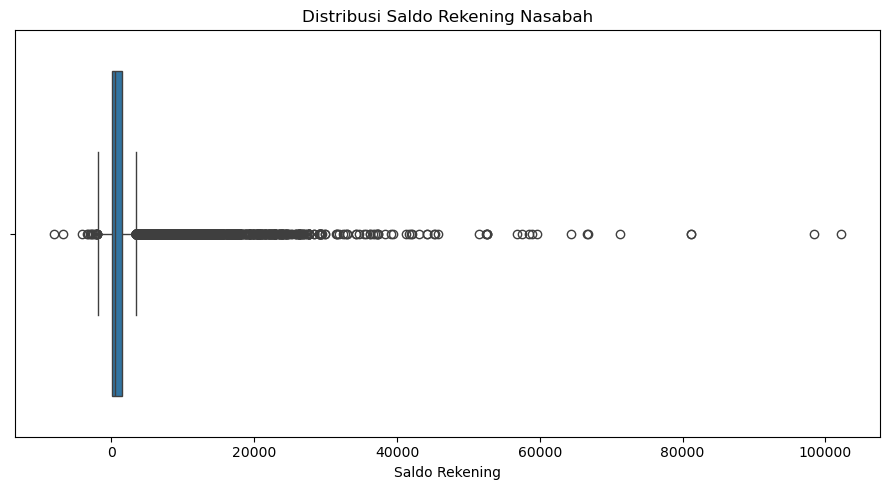

In [7]:

# NIM: 202431146
# EDA - Distribusi Saldo Nasabah

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="balance"
)

plt.title("Distribusi Saldo Rekening Nasabah")
plt.xlabel("Saldo Rekening")

plt.tight_layout()
plt.show()


In [8]:

# NIM: 202431146
# Preprocessing - Menentukan fitur dan target Naive Bayes

X_nb = df.drop(columns=["y", "duration"])
y_nb = df["y"].map({"no": 0, "yes": 1})

print("Ukuran fitur:", X_nb.shape)
print("Ukuran target:", y_nb.shape)

print("\nDistribusi target:")
print(y_nb.value_counts())


Ukuran fitur: (45211, 15)
Ukuran target: (45211,)

Distribusi target:
y
0    39922
1     5289
Name: count, dtype: int64


In [9]:

# NIM: 202431146
# Membagi data training dan testing

from sklearn.model_selection import train_test_split

X_train_nb, X_test_nb, y_train_nb, y_test_nb = train_test_split(
    X_nb,
    y_nb,
    test_size=0.2,
    random_state=42,
    stratify=y_nb
)

print("Data training:", X_train_nb.shape)
print("Data testing:", X_test_nb.shape)

print("\nDistribusi target training:")
print(y_train_nb.value_counts(normalize=True))

print("\nDistribusi target testing:")
print(y_test_nb.value_counts(normalize=True))


Data training: (36168, 15)
Data testing: (9043, 15)

Distribusi target training:
y
0    0.883018
1    0.116982
Name: proportion, dtype: float64

Distribusi target testing:
y
0    0.883003
1    0.116997
Name: proportion, dtype: float64


In [10]:

# NIM: 202431146
# Membuat preprocessing Naive Bayes

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

kolom_numerik = X_train_nb.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

kolom_kategorikal = X_train_nb.select_dtypes(
    include=["object", "str", "category"]
).columns.tolist()

print("Kolom numerik:", kolom_numerik)
print("Kolom kategorikal:", kolom_kategorikal)

preprocessor_nb = ColumnTransformer(
    transformers=[
        ("numerik", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]), kolom_numerik),

        ("kategorikal", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ), kolom_kategorikal)
    ]
)

print("\nPreprocessing berhasil dibuat!")


Kolom numerik: ['age', 'balance', 'day', 'campaign', 'pdays', 'previous']
Kolom kategorikal: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']

Preprocessing berhasil dibuat!


In [11]:

# NIM: 202431146
# Training model Gaussian Naive Bayes

from sklearn.naive_bayes import GaussianNB

model_nb = Pipeline([
    ("preprocessing", preprocessor_nb),
    ("classifier", GaussianNB())
])

model_nb.fit(X_train_nb, y_train_nb)

print("Training Gaussian Naive Bayes berhasil!")


Training Gaussian Naive Bayes berhasil!


In [12]:

# NIM: 202431146
# Prediksi data testing menggunakan Naive Bayes

y_pred_nb = model_nb.predict(X_test_nb)

print("Prediksi berhasil!")

print("\n10 hasil prediksi pertama:")
print(y_pred_nb[:10])

print("\n10 target aktual pertama:")
print(y_test_nb.values[:10])


Prediksi berhasil!

10 hasil prediksi pertama:
[0 0 0 0 0 0 0 1 0 0]

10 target aktual pertama:
[0 0 0 0 0 0 0 1 0 0]


In [13]:

# NIM: 202431146
# Evaluasi model Gaussian Naive Bayes

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

accuracy_nb = accuracy_score(y_test_nb, y_pred_nb)
precision_nb = precision_score(
    y_test_nb, y_pred_nb, zero_division=0
)
recall_nb = recall_score(
    y_test_nb, y_pred_nb, zero_division=0
)
f1_nb = f1_score(
    y_test_nb, y_pred_nb, zero_division=0
)

print("=== EVALUASI NAIVE BAYES ===")
print(f"Accuracy  : {accuracy_nb:.4f}")
print(f"Precision : {precision_nb:.4f}")
print(f"Recall    : {recall_nb:.4f}")
print(f"F1-Score  : {f1_nb:.4f}")

print("\n=== CLASSIFICATION REPORT ===")
print(classification_report(
    y_test_nb,
    y_pred_nb,
    target_names=["Tidak", "Ya"],
    zero_division=0
))


=== EVALUASI NAIVE BAYES ===
Accuracy  : 0.8452
Precision : 0.3708
Recall    : 0.4641
F1-Score  : 0.4123

=== CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

       Tidak       0.93      0.90      0.91      7985
          Ya       0.37      0.46      0.41      1058

    accuracy                           0.85      9043
   macro avg       0.65      0.68      0.66      9043
weighted avg       0.86      0.85      0.85      9043



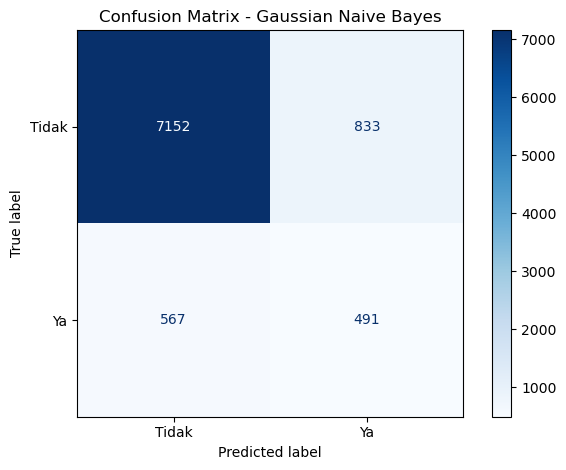

True Negative : 7152
False Positive: 833
False Negative: 567
True Positive : 491


In [14]:

# NIM: 202431146
# Visualisasi Confusion Matrix Naive Bayes

from sklearn.metrics import ConfusionMatrixDisplay

cm_nb = confusion_matrix(y_test_nb, y_pred_nb)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_nb,
    display_labels=["Tidak", "Ya"]
)

disp.plot(cmap="Blues", values_format="d")

plt.title("Confusion Matrix - Gaussian Naive Bayes")
plt.tight_layout()
plt.show()

print("True Negative :", cm_nb[0, 0])
print("False Positive:", cm_nb[0, 1])
print("False Negative:", cm_nb[1, 0])
print("True Positive :", cm_nb[1, 1])


In [15]:

# NIM: 202431146
# Regresi Linear - Menentukan fitur dan target

# Target berupa saldo rekening nasabah
y_lr = df["balance"]

# Fitur tidak menyertakan balance, y, dan duration
X_lr = df.drop(columns=["balance", "y", "duration"])

print("=== REGRESI LINEAR ===")
print("Jumlah fitur:", X_lr.shape[1])
print("Jumlah data:", X_lr.shape[0])

print("\nStatistik target balance:")
print(y_lr.describe())


=== REGRESI LINEAR ===
Jumlah fitur: 14
Jumlah data: 45211

Statistik target balance:
count     45211.000000
mean       1362.272058
std        3044.765829
min       -8019.000000
25%          72.000000
50%         448.000000
75%        1428.000000
max      102127.000000
Name: balance, dtype: float64


In [16]:

# NIM: 202431146
# Pembagian data untuk Regresi Linear

X_train_lr, X_test_lr, y_train_lr, y_test_lr = train_test_split(
    X_lr,
    y_lr,
    test_size=0.2,
    random_state=42
)

print("Data training:", X_train_lr.shape)
print("Data testing:", X_test_lr.shape)


Data training: (36168, 14)
Data testing: (9043, 14)


In [17]:

# NIM: 202431146
# Preprocessing Regresi Linear

kolom_numerik_lr = X_train_lr.select_dtypes(
    include=["number"]
).columns.tolist()

kolom_kategorikal_lr = X_train_lr.select_dtypes(
    include=["object", "str", "category"]
).columns.tolist()

preprocessor_lr = ColumnTransformer(
    transformers=[
        ("numerik", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]), kolom_numerik_lr),

        ("kategorikal", OneHotEncoder(
            handle_unknown="ignore"
        ), kolom_kategorikal_lr)
    ]
)

print("Kolom numerik:", kolom_numerik_lr)
print("Kolom kategorikal:", kolom_kategorikal_lr)
print("\nPreprocessing Regresi Linear berhasil dibuat!")


Kolom numerik: ['age', 'day', 'campaign', 'pdays', 'previous']
Kolom kategorikal: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']

Preprocessing Regresi Linear berhasil dibuat!


In [18]:

# NIM: 202431146
# Training Model Regresi Linear

from sklearn.linear_model import LinearRegression

model_lr = Pipeline([
    ("preprocessing", preprocessor_lr),
    ("regressor", LinearRegression())
])

model_lr.fit(X_train_lr, y_train_lr)

print("Training Regresi Linear berhasil!")


Training Regresi Linear berhasil!


In [19]:

# NIM: 202431146
# Prediksi saldo rekening

y_pred_lr = model_lr.predict(X_test_lr)

hasil_lr = pd.DataFrame({
    "Saldo Aktual": y_test_lr.values,
    "Saldo Prediksi": y_pred_lr
})

print("10 hasil prediksi pertama:")
display(hasil_lr.head(10))


10 hasil prediksi pertama:


,Saldo Aktual,Saldo Prediksi
0,580,1027.375131
1,3644,1774.592316
2,538,1719.051868
3,1773,2073.175495
4,217,1497.108020
5,1134,913.084756
6,1085,899.117183
7,127,1726.597065
8,3,710.680842
9,258,1142.910587


In [20]:

# NIM: 202431146
# Evaluasi Model Regresi Linear

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import numpy as np

mae_lr = mean_absolute_error(y_test_lr, y_pred_lr)
mse_lr = mean_squared_error(y_test_lr, y_pred_lr)
rmse_lr = np.sqrt(mse_lr)
r2_lr = r2_score(y_test_lr, y_pred_lr)

print("=== EVALUASI REGRESI LINEAR ===")
print(f"MAE  : {mae_lr:.4f}")
print(f"MSE  : {mse_lr:.4f}")
print(f"RMSE : {rmse_lr:.4f}")
print(f"R2   : {r2_lr:.4f}")


=== EVALUASI REGRESI LINEAR ===
MAE  : 1486.6445
MSE  : 9337688.8114
RMSE : 3055.7632
R2   : 0.0469


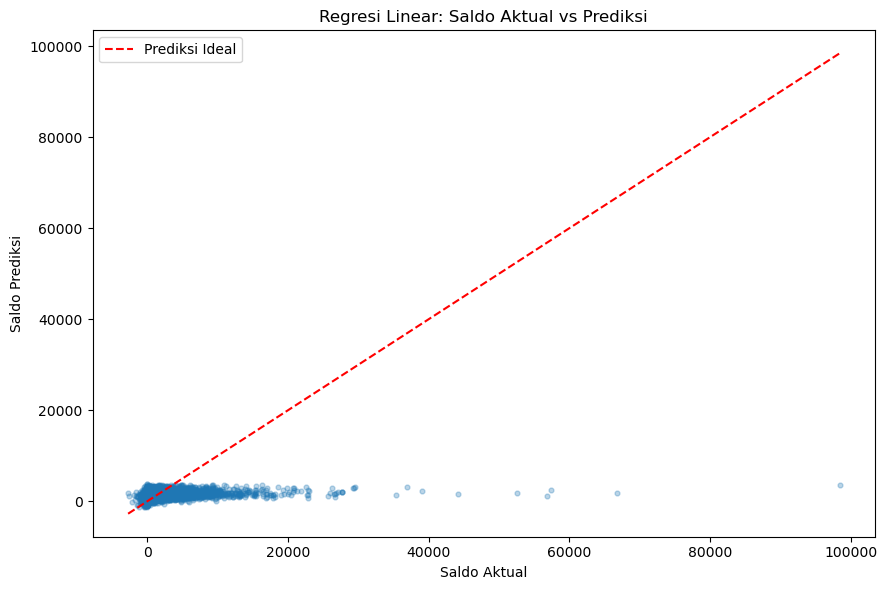

In [21]:

# NIM: 202431146
# Visualisasi Saldo Aktual vs Prediksi

plt.figure(figsize=(9, 6))

plt.scatter(
    y_test_lr,
    y_pred_lr,
    alpha=0.3,
    s=12
)

batas_min = min(y_test_lr.min(), y_pred_lr.min())
batas_max = max(y_test_lr.max(), y_pred_lr.max())

plt.plot(
    [batas_min, batas_max],
    [batas_min, batas_max],
    "r--",
    label="Prediksi Ideal"
)

plt.title("Regresi Linear: Saldo Aktual vs Prediksi")
plt.xlabel("Saldo Aktual")
plt.ylabel("Saldo Prediksi")
plt.legend()

plt.tight_layout()
plt.show()


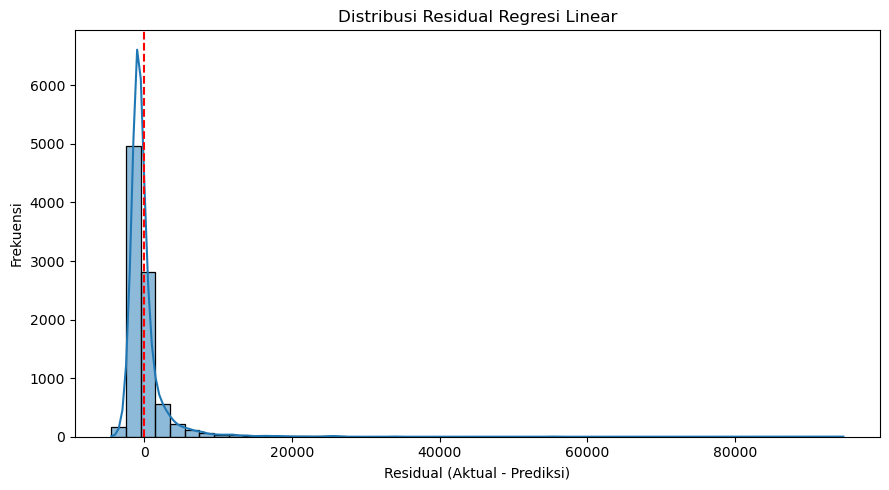

Rata-rata residual: -5.768749330663953
Standar deviasi residual: 3055.7577673827536


In [22]:

# NIM: 202431146
# Analisis Residual Regresi Linear

residual_lr = y_test_lr.values - y_pred_lr

plt.figure(figsize=(9, 5))

sns.histplot(
    residual_lr,
    bins=50,
    kde=True
)

plt.axvline(
    x=0,
    color="red",
    linestyle="--"
)

plt.title("Distribusi Residual Regresi Linear")
plt.xlabel("Residual (Aktual - Prediksi)")
plt.ylabel("Frekuensi")

plt.tight_layout()
plt.show()

print("Rata-rata residual:", np.mean(residual_lr))
print("Standar deviasi residual:", np.std(residual_lr))


In [23]:

# NIM: 202431146
# Rekap Hasil Evaluasi Kedua Algoritma

rekap_hasil = pd.DataFrame({
    "Algoritma": [
        "Gaussian Naive Bayes",
        "Regresi Linear"
    ],
    "Target": [
        "Berlangganan Deposito (y)",
        "Saldo Rekening (balance)"
    ],
    "Metrik Evaluasi": [
        "Accuracy, Precision, Recall, F1",
        "MAE, MSE, RMSE, R2"
    ],
    "Hasil Utama": [
        f"Accuracy: {accuracy_nb:.4f}; F1: {f1_nb:.4f}",
        f"RMSE: {rmse_lr:.4f}; R2: {r2_lr:.4f}"
    ]
})

display(rekap_hasil)


,Algoritma,Target,Metrik Evaluasi,Hasil Utama
0,Gaussian Naive Bayes,Berlangganan Deposito (y),"Accuracy, Precision, Recall, F1",Accuracy: 0.8452; F1: 0.4123
1,Regresi Linear,Saldo Rekening (balance),"MAE, MSE, RMSE, R2",RMSE: 3055.7632; R2: 0.0469
